# Score de Cobranzas 
**Trabajo Final – Introducción a Ciencia de Datos**
Autor: Noemi Ticona Angles

Notebook reproducible: cartera de tarjetas de crédito,un  enfoque Híbrido Metodológico que combina CRISP-DM con la agilidad técnica del pipeline de desarrollo OSEMN.

> Los datos son **reales ofuscados mediante la inserción de ruido**: esto para analisis de teorico practico  del módulo

### Diccionario de Datos: `dataset.csv` (Variables Localizadas)

El conjunto de datos de la cartera de tarjetas de crédito  cuenta con la siguiente definición de variables:

| Variable | Tipo | Descripción |
| :--- | :--- | :--- |
| **COD_CLIENTE** | Numérico | Código interno único de identificación del cliente. |
| **MTO_LIMITE_CREDITO** | Numérico | Límite de crédito de la tarjeta (en Bs). |
| **COD_SEXO** | Categórico | Sexo del cliente (1 = Hombre; 2 = Mujer). |
| **COD_NIVEL_EDUCATIVO** | Categórico | Nivel educativo (1 = Posgrado; 2 = Universidad; 3 = Secundaria/Técnico; 4 = Otros). |
| **COD_ESTADO_CIVIL** | Categórico | Estado civil (1 = Casado; 2 = Soltero; 3 = Otros). |
| **EDAD** | Numérico | Edad del cliente en años. |
| **DEPARTAMENTO** | Categórico | Departamento de residencia en Bolivia. |
| **TIPO_EMPLEO** | Categórico | Situación laboral del cliente. |
| **EST_PAGO_M0** | Numérico | Estado de pago del mes de corte (agosto 2026). |
| **EST_PAGO_M1** | Numérico | Estado de pago 1 mes antes (julio). |
| **EST_PAGO_M2** | Numérico | Estado de pago 2 meses antes (junio). |
| **EST_PAGO_M3** | Numérico | Estado de pago 3 meses antes (mayo). |
| **EST_PAGO_M4** | Numérico | Estado de pago 4 meses antes (abril). |
| **EST_PAGO_M5** | Numérico | Estado de pago 5 meses antes (marzo). |
| **MTO_FACTURADO_M0** | Numérico | Monto facturado en el mes de corte (Bs). |
| **MTO_FACTURADO_M1** | Numérico | Monto facturado 1 mes antes. |
| **MTO_FACTURADO_M2** | Numérico | Monto facturado 2 meses antes. |
| **MTO_FACTURADO_M3** | Numérico | Monto facturado 3 meses antes. |
| **MTO_FACTURADO_M4** | Numérico | Monto facturado 4 meses antes. |
| **MTO_FACTURADO_M5** | Numérico | Monto facturado 5 meses antes. |
| **MTO_PAGADO_M0** | Numérico | Monto pagado en el mes de corte (Bs). |
| **MTO_PAGADO_M1** | Numérico | Monto pagado 1 mes antes. |
| **MTO_PAGADO_M2** | Numérico | Monto pagado 2 meses antes. |
| **MTO_PAGADO_M3** | Numérico | Monto pagado 3 meses antes. |
| **MTO_PAGADO_M4** | Numérico | Monto pagado 4 meses antes. |
| **MTO_PAGADO_M5** | Numérico | Monto pagado 5 meses antes. |
| **IND_INCUMPLE_MES_SIG** | Binario | Variable objetivo original (1 = No paga el mes siguiente; 0 = Paga lo nuevo). |

### Variable Objetivo para Cobranzas (`PAGA`):

Para ajustar el modelo al universo en mora y predecir la probabilidad de recuperación, se define la variable objetivo real como:
$$\text{PAGA} = 1 - \text{IND_INCUMPLE_MES_SIG}$$

* **`PAGA = 1`**: El cliente **Sí Paga** (recuperación exitosa).
* **`PAGA = 0`**: El cliente **No Paga** (incumplimiento / pérdida).

## 0. Importanción de librerias
  Definición e importanción de librerias usadas

In [ ]:
"""Score de Cobranzas  .
Análisis completo: EDA, limpieza, variables, comparación de 8 algoritmos, ajuste, score y deciles."""
import json, time, warnings, sys
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, brier_score_loss)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
warnings.filterwarnings("ignore")

DATA = "dataset.csv"
OUT = "out"; FIG = f"{OUT}/fig"
import os; os.makedirs(FIG, exist_ok=True)
RS = 42
R = {}

In [ ]:
# ---------- estilo de gráficos ----------
AZUL, NAR, GRIS, VERDE = "#2a78d6", "#eb6834", "#8a8984", "#1baf7a"
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e0",
                     "grid.linewidth": .6, "axes.axisbelow": True, "axes.edgecolor": "#8a8984",
                     "figure.dpi": 150, "savefig.bbox": "tight"})
def save(name): plt.savefig(f"{FIG}/{name}.png", dpi=170); plt.show()

## 1. Carga de datos

In [ ]:
# ================= 1. CARGA =================
#cargar el csv
df = pd.read_csv(DATA)

display(df.head())
# Inicializamos un diccionario descriptivo para almacenar las métricas y reportes del proceso


,COD_CLIENTE,MTO_LIMITE_CREDITO,COD_SEXO,COD_NIVEL_EDUCATIVO,COD_ESTADO_CIVIL,EDAD,DEPARTAMENTO,TIPO_EMPLEO,EST_PAGO_M0,EST_PAGO_M1,...,MTO_FACTURADO_M3,MTO_FACTURADO_M4,MTO_FACTURADO_M5,MTO_PAGADO_M0,MTO_PAGADO_M1,MTO_PAGADO_M2,MTO_PAGADO_M3,MTO_PAGADO_M4,MTO_PAGADO_M5,IND_INCUMPLE_MES_SIG
0,1,127000,1,2,1,29,Santa Cruz,Dependiente,0,1,...,23059,4358,0,3799,289,23059,4358,0,1914,0
1,2,6000,2,3,1,45,Cochabamba,Dependiente,-1,0,...,1601,1841,1766,1696,386,1601,373,31,2141,0
2,3,41500,1,1,1,34,La Paz,Comerciante,-1,0,...,3255,0,5489,5881,2007,3255,0,5489,3356,0
3,4,27000,2,3,2,24,Santa Cruz,Dependiente,0,0,...,9736,13362,14469,4921,3705,0,13362,2364,1073,0
4,5,32500,1,2,1,31,Santa Cruz,Dependiente,0,0,...,29801,26480,29212,2278,1252,29801,1952,2231,2111,0



##Analisis del estado del dataset actual
Calidad de datos



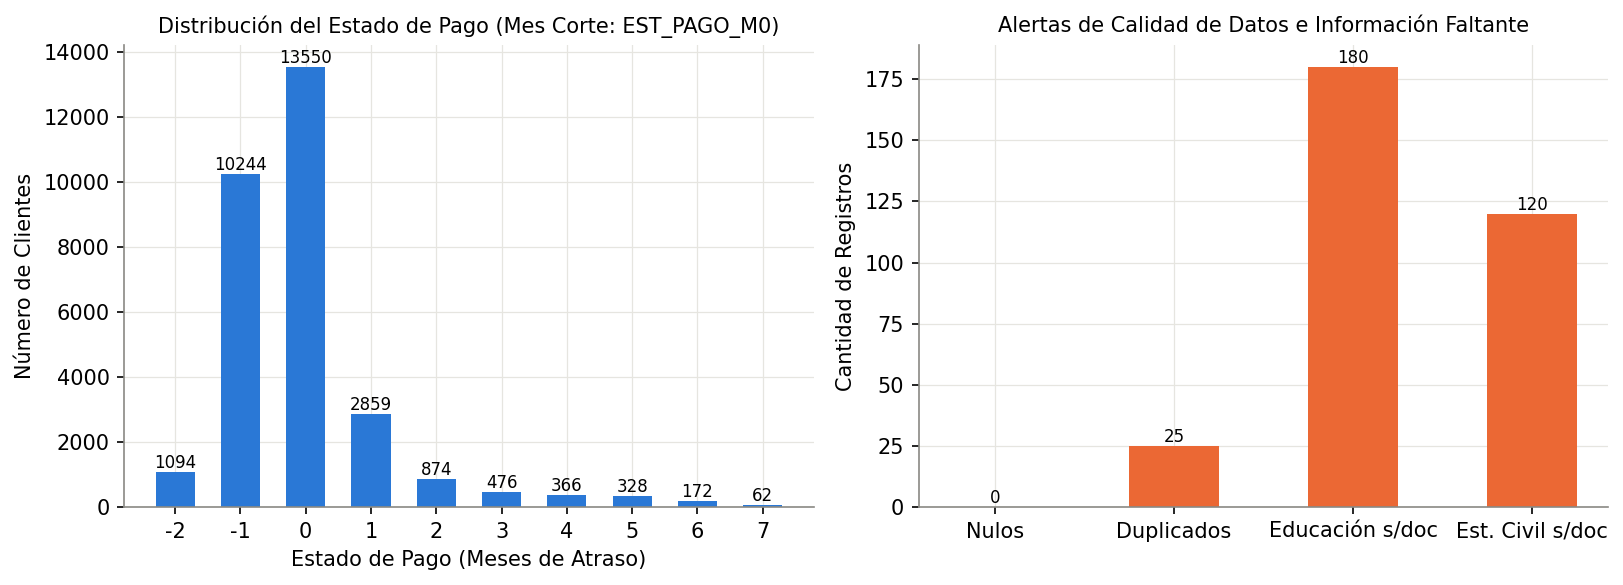

In [ ]:
# Visualización de las métricas iniciales del reporte
reporte_metricas = {}

reporte_metricas["total_registros"] = len(df)
reporte_metricas["tasa_pago_cartera_total"] = 1 - df.IND_INCUMPLE_MES_SIG.mean()
reporte_metricas["total_valores_nulos"] = int(df.isna().sum().sum())
reporte_metricas["total_duplicados"] = int(df.drop(columns="COD_CLIENTE").duplicated().sum())
reporte_metricas["educacion_sin_documentar"] = int(df.COD_NIVEL_EDUCATIVO.isin([0, 5, 6]).sum())
reporte_metricas["estado_civil_sin_documentar"] = int((df.COD_ESTADO_CIVIL == 0).sum())

PAYS = ["EST_PAGO_M0", "EST_PAGO_M1", "EST_PAGO_M2", "EST_PAGO_M3", "EST_PAGO_M4", "EST_PAGO_M5"]
BILLS = [f"MTO_FACTURADO_M{i}" for i in range(6)]
PAMTS = [f"MTO_PAGADO_M{i}" for i in range(6)]

reporte_metricas["clientes_sin_atraso_historico"] = int(df[PAYS].isin([-2, -1, 0]).any(axis=1).sum())
reporte_metricas["clientes_factura_negativa"] = int((df[BILLS] < 0).any(axis=1).sum())
reporte_metricas["distribucion_estado_pago_mes_corte"] = df.EST_PAGO_M0.value_counts().sort_index().to_dict()


fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# 1. Gráfico de la distribución de estado de pago en el mes de corte
estados = list(reporte_metricas["distribucion_estado_pago_mes_corte"].keys())
cantidades = list(reporte_metricas["distribucion_estado_pago_mes_corte"].values())

b1 = ax[0].bar([str(e) for e in estados], cantidades, color=AZUL, width=0.6)
ax[0].bar_label(b1, fmt='%d', fontsize=8)
ax[0].set_title("Distribución del Estado de Pago (Mes Corte: EST_PAGO_M0)", fontsize=10)
ax[0].set_xlabel("Estado de Pago (Meses de Atraso)")
ax[0].set_ylabel("Número de Clientes")

# 2. Resumen de Calidad de Datos (Nulos, Duplicados, Sin Documentar)
categorias = ['Nulos', 'Duplicados', 'Educación s/doc', 'Est. Civil s/doc']
valores = [
    reporte_metricas["total_valores_nulos"],
    reporte_metricas["total_duplicados"],
    reporte_metricas["educacion_sin_documentar"],
    reporte_metricas["estado_civil_sin_documentar"]
]

b2 = ax[1].bar(categorias, valores, color=NAR, width=0.5)
ax[1].bar_label(b2, fmt='%d', fontsize=8)
ax[1].set_title("Alertas de Calidad de Datos e Información Faltante", fontsize=10)
ax[1].set_ylabel("Cantidad de Registros")

plt.tight_layout()
save("00_metricas_iniciales_carga")

## 2. Preparación: universo en mora, limpieza y variables nuevas

In [ ]:
# ================= 2. UNIVERSO EN MORA Y LIMPIEZA =================
m = df[df.EST_PAGO_M0 >= 1].copy()
R["n_mora_bruto"] = len(m)
dups = m.drop(columns="COD_CLIENTE").duplicated()
R["dup_mora"] = int(dups.sum()); m = m[~dups].copy()
m["PAGA"] = 1 - m.IND_INCUMPLE_MES_SIG
m["COD_NIVEL_EDUCATIVO"] = m.COD_NIVEL_EDUCATIVO.replace({0: 4, 5: 4, 6: 4})
m["COD_ESTADO_CIVIL"] = m.COD_ESTADO_CIVIL.replace({0: 3})
for c in PAYS: m[c] = m[c].clip(lower=0)  # -2,-1,0 -> 0 (sin atraso)
# outliers (IQR) - solo conteo, no se eliminan
iqr = {}
for c in ["MTO_LIMITE_CREDITO", "MTO_FACTURADO_M0", "MTO_PAGADO_M0", "EDAD"]:
    q1, q3 = m[c].quantile([.25, .75]); lim = q3 + 1.5 * (q3 - q1)
    iqr[c] = int((m[c] > lim).sum())
R["outliers_iqr"] = iqr
# variables nuevas
m["MAX_ATRASO"] = m[PAYS].max(axis=1)
m["N_MESES_ATRASO"] = (m[PAYS] > 0).sum(axis=1)
m["TENDENCIA_ATRASO"] = m.EST_PAGO_M0 - m.EST_PAGO_M1
m["UTILIZACION"] = (m.MTO_FACTURADO_M0 / m.MTO_LIMITE_CREDITO).clip(-1, 3)
m["RATIO_PAGO"] = np.where(m.MTO_FACTURADO_M1 > 0, m.MTO_PAGADO_M0 / m.MTO_FACTURADO_M1.where(m.MTO_FACTURADO_M1 > 0, 1), 1.0)
m["RATIO_PAGO"] = m.RATIO_PAGO.clip(0, 2)
m["PROM_FACTURADO"] = m[BILLS].mean(axis=1); m["PROM_PAGADO"] = m[PAMTS].mean(axis=1)
m["EDAD_RANGO"] = pd.cut(m.EDAD, [20, 30, 40, 50, 100], labels=["21-30", "31-40", "41-50", "51+"])
R["n_mora"] = len(m); R["tasa_pago_mora"] = m.PAGA.mean()

DEMO_CAT = ["COD_SEXO", "COD_NIVEL_EDUCATIVO", "COD_ESTADO_CIVIL"]
OTRAS_CAT = ["DEPARTAMENTO", "TIPO_EMPLEO"]
NUM_BASE = ["MTO_LIMITE_CREDITO", "EDAD"] + PAYS + BILLS + PAMTS
NUEVAS = ["MAX_ATRASO", "N_MESES_ATRASO", "TENDENCIA_ATRASO", "UTILIZACION", "RATIO_PAGO", "PROM_FACTURADO", "PROM_PAGADO"]
MONEY = ["MTO_LIMITE_CREDITO"] + BILLS + PAMTS + ["PROM_FACTURADO", "PROM_PAGADO"]
R["n_vars_final"] = len(NUM_BASE + NUEVAS + DEMO_CAT + OTRAS_CAT)

In [ ]:
# Visualizar cómo queda el dataset 'm' después del Paso 2
print(f"Dimensiones del dataset de mora: {m.shape[0]} filas y {m.shape[1]} columnas")
display(m.head())

Dimensiones del dataset de mora: 5133 filas y 36 columnas


,COD_CLIENTE,MTO_LIMITE_CREDITO,COD_SEXO,COD_NIVEL_EDUCATIVO,COD_ESTADO_CIVIL,EDAD,DEPARTAMENTO,TIPO_EMPLEO,EST_PAGO_M0,EST_PAGO_M1,...,IND_INCUMPLE_MES_SIG,PAGA,MAX_ATRASO,N_MESES_ATRASO,TENDENCIA_ATRASO,UTILIZACION,RATIO_PAGO,PROM_FACTURADO,PROM_PAGADO,EDAD_RANGO
10,11,69000,2,3,2,35,Oruro,Comerciante,3,2,...,0,1,3,4,1,0.482130,0.033192,28885.500000,4131.833333,31-40
14,15,20500,2,3,2,44,La Paz,Comerciante,1,0,...,1,0,1,1,1,0.481024,0.054437,11199.666667,2666.000000,41-50
16,17,25000,2,2,1,45,Santa Cruz,Dependiente,1,0,...,0,1,1,1,1,0.530600,0.042791,14753.500000,5077.333333,41-50
21,22,11000,1,2,2,26,Santa Cruz,Dependiente,1,0,...,0,1,1,2,1,0.630727,0.000000,7326.333333,1276.000000,21-30
22,23,24500,2,1,3,38,Cochabamba,Comerciante,4,3,...,1,0,4,6,1,0.658490,0.000000,15958.666667,373.833333,31-40


In [ ]:
# Análisis e impresión de las variables promedio creadas en el Paso 2
promedio_montos = m[["PROM_FACTURADO", "PROM_PAGADO"]]

print("--- Estadísticas Descriptivas de Facturación y Pago Promedio ---")
display(promedio_montos.describe())

print("\n--- Vista previa de los primeros 10 clientes ---")
display(promedio_montos.head(10))

--- Estadísticas Descriptivas de Facturación y Pago Promedio ---


,PROM_FACTURADO,PROM_PAGADO
count,5133.000000,5133.000000
mean,12490.709949,2516.336873
std,13741.128148,4130.580033
min,-7.833333,0.000000
25%,4536.666667,440.666667
50%,8321.000000,1173.666667
75%,15544.166667,2910.333333
max,213193.166667,72768.833333



--- Vista previa de los primeros 10 clientes ---


,PROM_FACTURADO,PROM_PAGADO
10,28885.500000,4131.833333
14,11199.666667,2666.000000
16,14753.500000,5077.333333
21,7326.333333,1276.000000
22,15958.666667,373.833333
27,9790.833333,2647.833333
39,20540.666667,2785.666667
45,6312.500000,1828.000000
48,8195.166667,5408.666667
50,15906.333333,6376.166667


In [ ]:
# Calcular y mostrar la tabla descriptiva de las variables clave del universo en mora
desc_mora = m[["MTO_LIMITE_CREDITO", "EDAD", "MTO_FACTURADO_M0", "MTO_PAGADO_M0", "UTILIZACION", "RATIO_PAGO", "MAX_ATRASO"]].describe().T

print("--- Estadísticas Descriptivas del Universo en Mora ---")
display(desc_mora)

--- Estadísticas Descriptivas del Universo en Mora ---


,count,mean,std,min,25%,50%,75%,max
MTO_LIMITE_CREDITO,5133.0,22120.981882,21887.029574,2000.00000,9000.000000,16000.000000,27000.000000,280000.000
EDAD,5133.0,38.760569,8.603194,22.00000,32.000000,37.000000,43.000000,75.000
MTO_FACTURADO_M0,5133.0,12763.111241,14418.097533,45.00000,4409.000000,8509.000000,16219.000000,229685.000
MTO_PAGADO_M0,5133.0,219.377557,501.436905,0.00000,0.000000,0.000000,237.000000,6310.000
UTILIZACION,5133.0,0.617224,0.305188,0.00027,0.404628,0.624079,0.846545,1.396
RATIO_PAGO,5133.0,0.050927,0.178480,0.00000,0.000000,0.000000,0.040891,1.000
MAX_ATRASO,5133.0,2.165595,1.507014,1.00000,1.000000,2.000000,3.000000,7.000


\## 3. Exploración de los datos (Explore)

In [ ]:
# ================= 3. EDA =================
# KPIs descriptivos
tr = pd.cut(m.EST_PAGO_M0, [0, 1, 2, 9], labels=["1 mes", "2 meses", "3+ meses"])
kp = m.groupby(tr).PAGA.agg(["size", "mean"]); kp["pct"] = kp["size"] / len(m)
R["kpi_tramo"] = {k: {"n": int(v["size"]), "pct": float(v.pct), "tasa_pago": float(v["mean"])} for k, v in kp.iterrows()}
R["util_prom"] = float(m.UTILIZACION.mean()); R["ratio_pago_prom"] = float(m.RATIO_PAGO.mean())
R["util_med"] = float(m.UTILIZACION.median()); R["ratio_pago_med"] = float(m.RATIO_PAGO.median())
desc = m[["MTO_LIMITE_CREDITO", "EDAD", "MTO_FACTURADO_M0", "MTO_PAGADO_M0", "UTILIZACION", "RATIO_PAGO", "MAX_ATRASO"]].describe().T
desc.to_csv(f"{OUT}/descriptivos.csv"); R["desc"] = desc.round(2).to_dict(orient="index")
cat_tab = {}
for c, lab in [("COD_SEXO", {1: "Hombre", 2: "Mujer"}), ("COD_NIVEL_EDUCATIVO", {1: "Posgrado", 2: "Universidad", 3: "Secundaria", 4: "Otros"}),
               ("COD_ESTADO_CIVIL", {1: "Casado", 2: "Soltero", 3: "Otros"}), ("EDAD_RANGO", None), ("DEPARTAMENTO", None), ("TIPO_EMPLEO", None)]:
    g = m.groupby(c, observed=True).PAGA.agg(["size", "mean"])
    cat_tab[c] = {(lab[k] if lab else str(k)): {"n": int(v["size"]), "tasa_pago": float(v["mean"])} for k, v in g.iterrows()}
R["cat_tab"] = cat_tab
# correlación con objetivo
corr = m[NUM_BASE + NUEVAS + ["PAGA"]].corr()["PAGA"].drop("PAGA").sort_values()
R["corr_top"] = corr.round(3).to_dict()

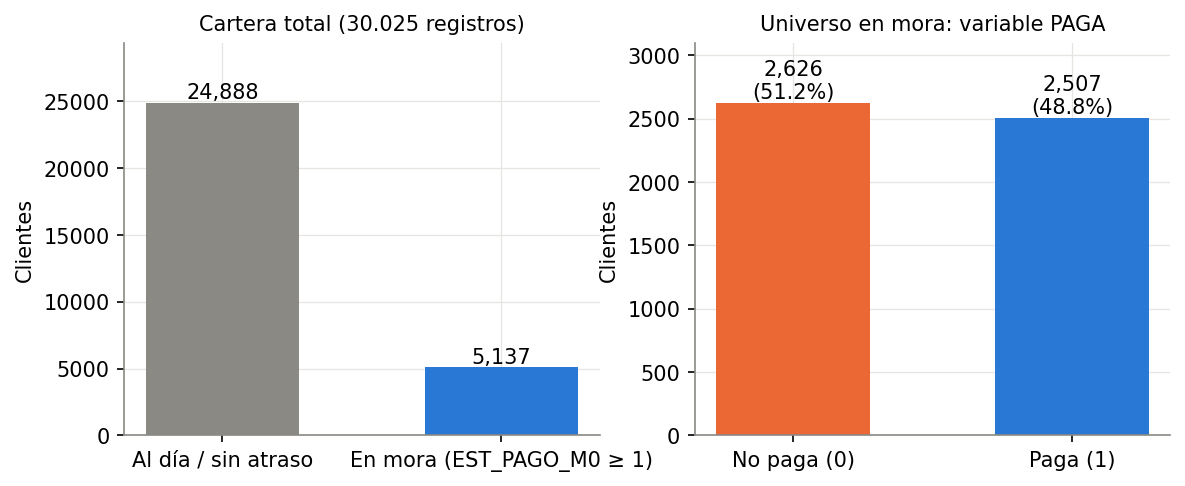

In [ ]:
# Fig 1: universo y clase objetivo
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
b = ax[0].bar(["Al día / sin atraso", "En mora (EST_PAGO_M0 ≥ 1)"], [len(df) - R["n_mora_bruto"], R["n_mora_bruto"]], color=[GRIS, AZUL], width=.55)
ax[0].bar_label(b, labels=[f"{len(df)-R['n_mora_bruto']:,}", f"{R['n_mora_bruto']:,}"]); ax[0].set_title(f"Cartera total ({len(df):,} registros)".replace(",", "."), fontsize=10)
vc = m.PAGA.value_counts().sort_index()
b = ax[1].bar(["No paga (0)", "Paga (1)"], vc.values, color=[NAR, AZUL], width=.55)
ax[1].bar_label(b, labels=[f"{v:,}\n({v/len(m):.1%})" for v in vc.values]); ax[1].set_title("Universo en mora: variable PAGA", fontsize=10)
for a in ax: a.set_ylabel("Clientes"); a.margins(y=.18)
save("01_universo_objetivo")

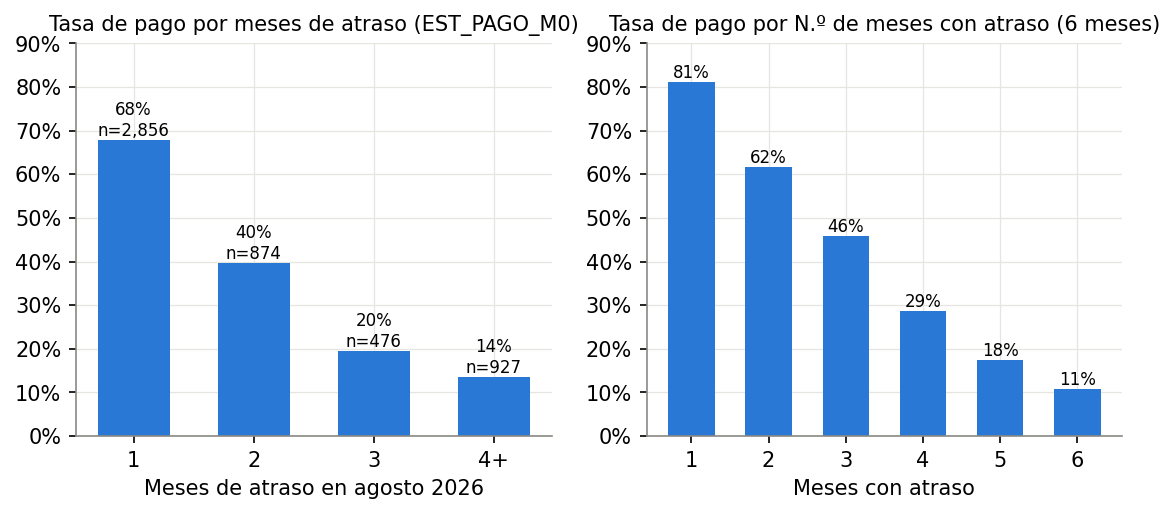

In [ ]:
# Fig 2: tasa de pago por meses de atraso actual y por MAX/N meses
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
g = m.assign(T=m.EST_PAGO_M0.clip(upper=4)).groupby("T").PAGA.agg(["mean", "size"])
b = ax[0].bar(["1", "2", "3", "4+"], g["mean"], color=AZUL, width=.6)
ax[0].bar_label(b, labels=[f"{v:.0%}\nn={n:,}" for v, n in zip(g["mean"], g["size"])], fontsize=8)
ax[0].set_title("Tasa de pago por meses de atraso (EST_PAGO_M0)", fontsize=10); ax[0].set_xlabel("Meses de atraso en agosto 2026"); ax[0].set_ylim(0, .9)
g = m.groupby("N_MESES_ATRASO").PAGA.agg(["mean", "size"])
b = ax[1].bar(g.index.astype(str), g["mean"], color=AZUL, width=.6)
ax[1].bar_label(b, labels=[f"{v:.0%}" for v in g["mean"]], fontsize=8)
ax[1].set_title("Tasa de pago por N.º de meses con atraso (6 meses)", fontsize=10); ax[1].set_xlabel("Meses con atraso"); ax[1].set_ylim(0, .9)
for a in ax: a.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1))
save("02_tasa_pago_atraso")

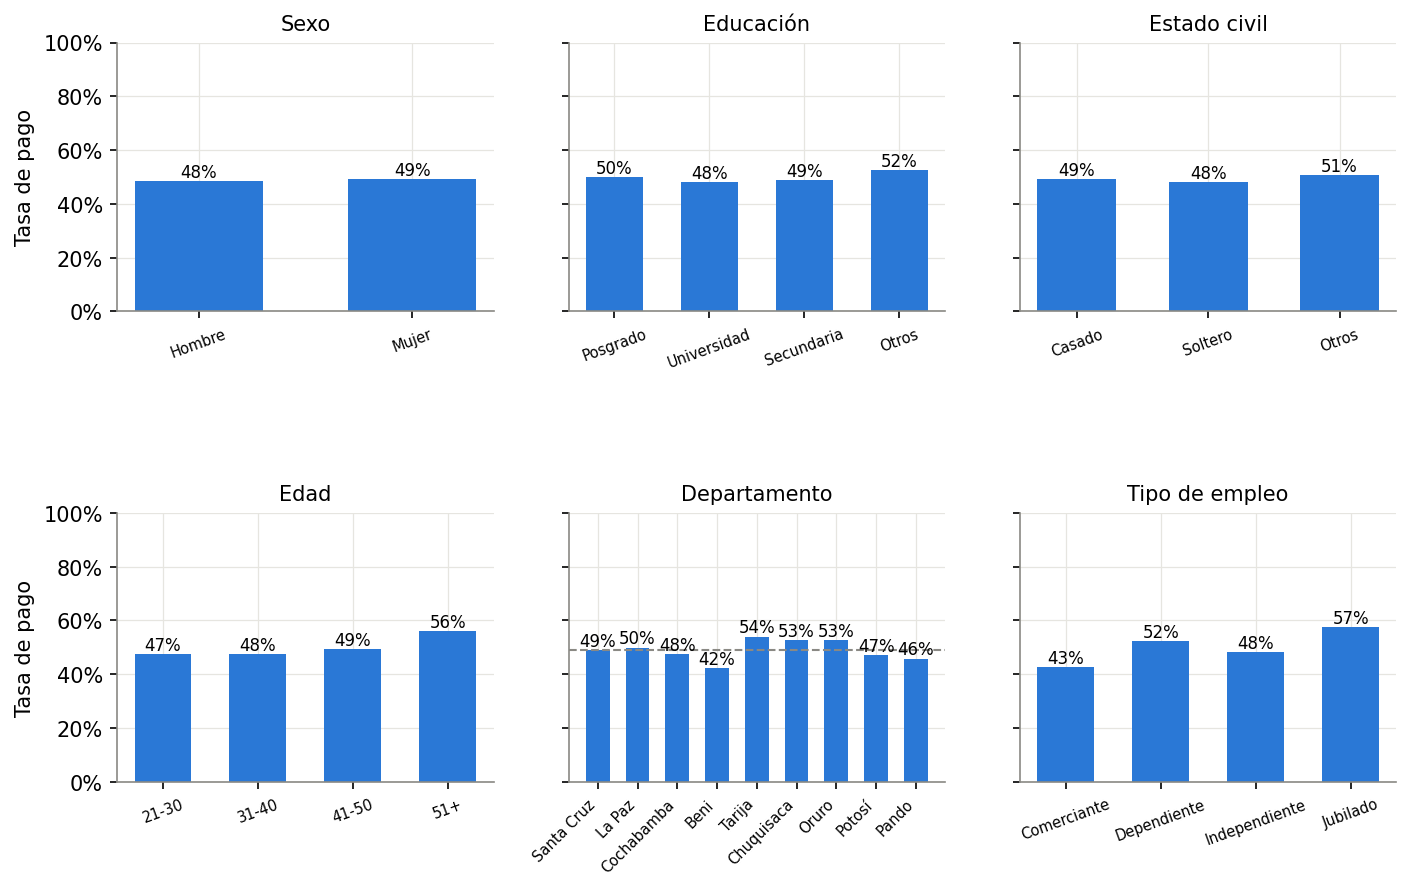

In [ ]:
# Fig 3: categóricas
fig, ax = plt.subplots(2, 3, figsize=(11, 6.4), sharey=True, gridspec_kw=dict(hspace=.75)); ax = ax.ravel()
for a, (c, d) in zip(ax, cat_tab.items()):
    if c == "DEPARTAMENTO": d = dict(sorted(d.items(), key=lambda kv: -kv[1]["n"]))
    ks = list(d.keys()); vs = [d[k]["tasa_pago"] for k in ks]
    b = a.bar(ks, vs, color=AZUL, width=.6); a.bar_label(b, labels=[f"{v:.0%}" for v in vs], fontsize=8)
    a.set_title({"COD_SEXO": "Sexo", "COD_NIVEL_EDUCATIVO": "Educación", "COD_ESTADO_CIVIL": "Estado civil", "EDAD_RANGO": "Edad", "DEPARTAMENTO": "Departamento", "TIPO_EMPLEO": "Tipo de empleo"}[c], fontsize=10)
    a.tick_params(axis="x", labelsize=7, rotation=35 if c == "DEPARTAMENTO" else 20)
    if c == "DEPARTAMENTO": plt.setp(a.get_xticklabels(), rotation=45, ha="right"); a.axhline(R["tasa_pago_mora"], color=GRIS, ls="--", lw=1)
for a in (ax[0], ax[3]): a.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1)); a.set_ylabel("Tasa de pago")
ax[0].set_ylim(0, 1)
save("03_categoricas")

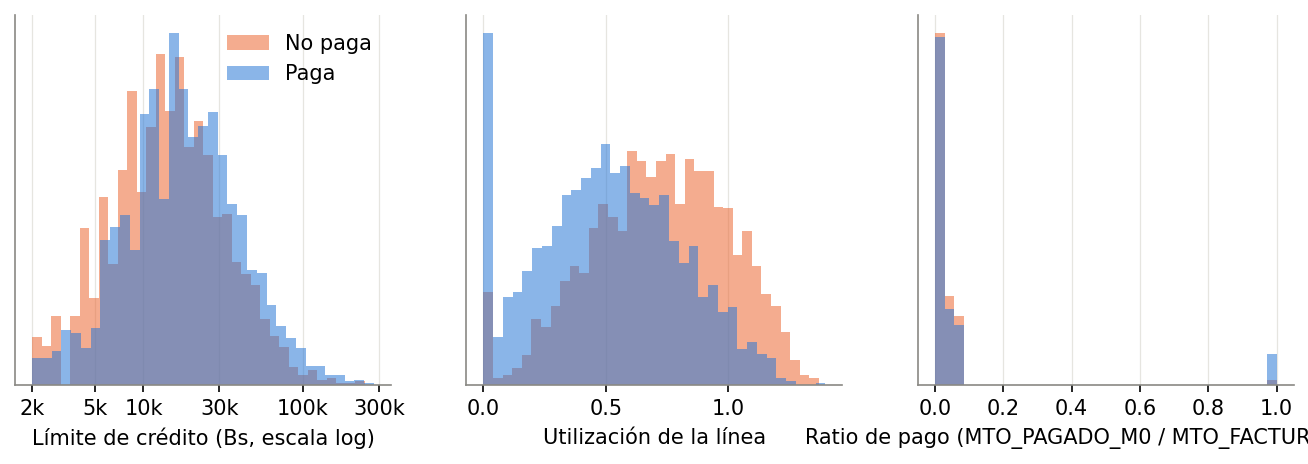

In [ ]:
# Fig 4: distribuciones continuas por clase
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
for a, c, lab in [(ax[0], "MTO_LIMITE_CREDITO", "Límite de crédito (Bs, escala log)"), (ax[1], "UTILIZACION", "Utilización de la línea"), (ax[2], "RATIO_PAGO", "Ratio de pago (MTO_PAGADO_M0 / MTO_FACTURADO_M1)")]:
    for cl, col, nm in [(0, NAR, "No paga"), (1, AZUL, "Paga")]:
        x = m.loc[m.PAGA == cl, c]
        if c == "MTO_LIMITE_CREDITO": x = np.log10(x)
        a.hist(x, bins=35, alpha=.55, color=col, label=nm, density=True)
    a.set_xlabel(lab); a.set_yticks([])
ax[0].set_xticks(np.log10([2000, 5000, 10000, 30000, 100000, 300000])); ax[0].set_xticklabels(["2k", "5k", "10k", "30k", "100k", "300k"])
ax[0].legend(frameon=False); save("04_distribuciones")

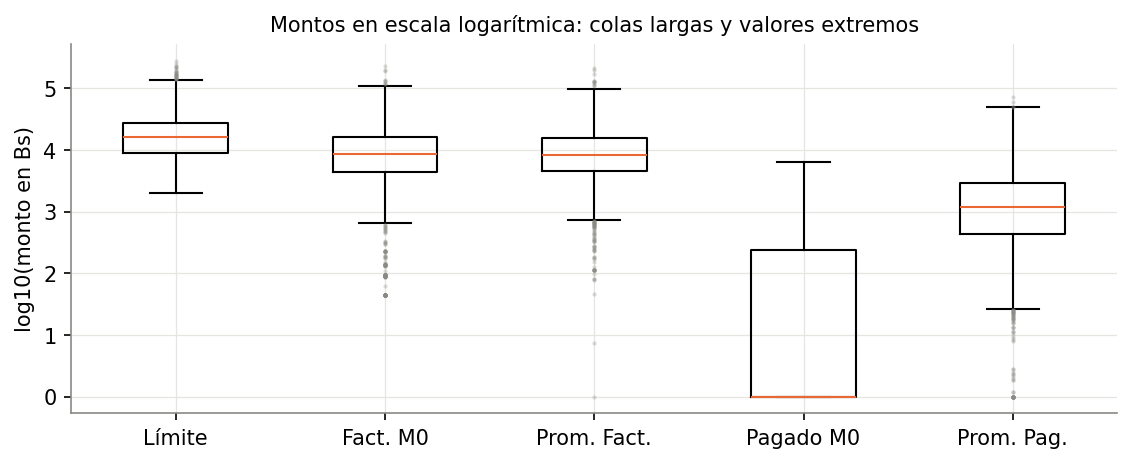

In [ ]:
# Fig 5: boxplots montos (outliers)
fig, ax = plt.subplots(figsize=(9, 3.2))
data = [np.log10(m[c].clip(lower=1)) for c in ["MTO_LIMITE_CREDITO", "MTO_FACTURADO_M0", "PROM_FACTURADO", "MTO_PAGADO_M0", "PROM_PAGADO"]]
ax.boxplot(data, tick_labels=["Límite", "Fact. M0", "Prom. Fact.", "Pagado M0", "Prom. Pag."], widths=.5,
           flierprops=dict(marker="o", ms=2, alpha=.3, mfc=GRIS, mec="none"), medianprops=dict(color=NAR))
ax.set_ylabel("log10(monto en Bs)"); ax.set_title("Montos en escala logarítmica: colas largas y valores extremos", fontsize=10)
save("05_boxplots")

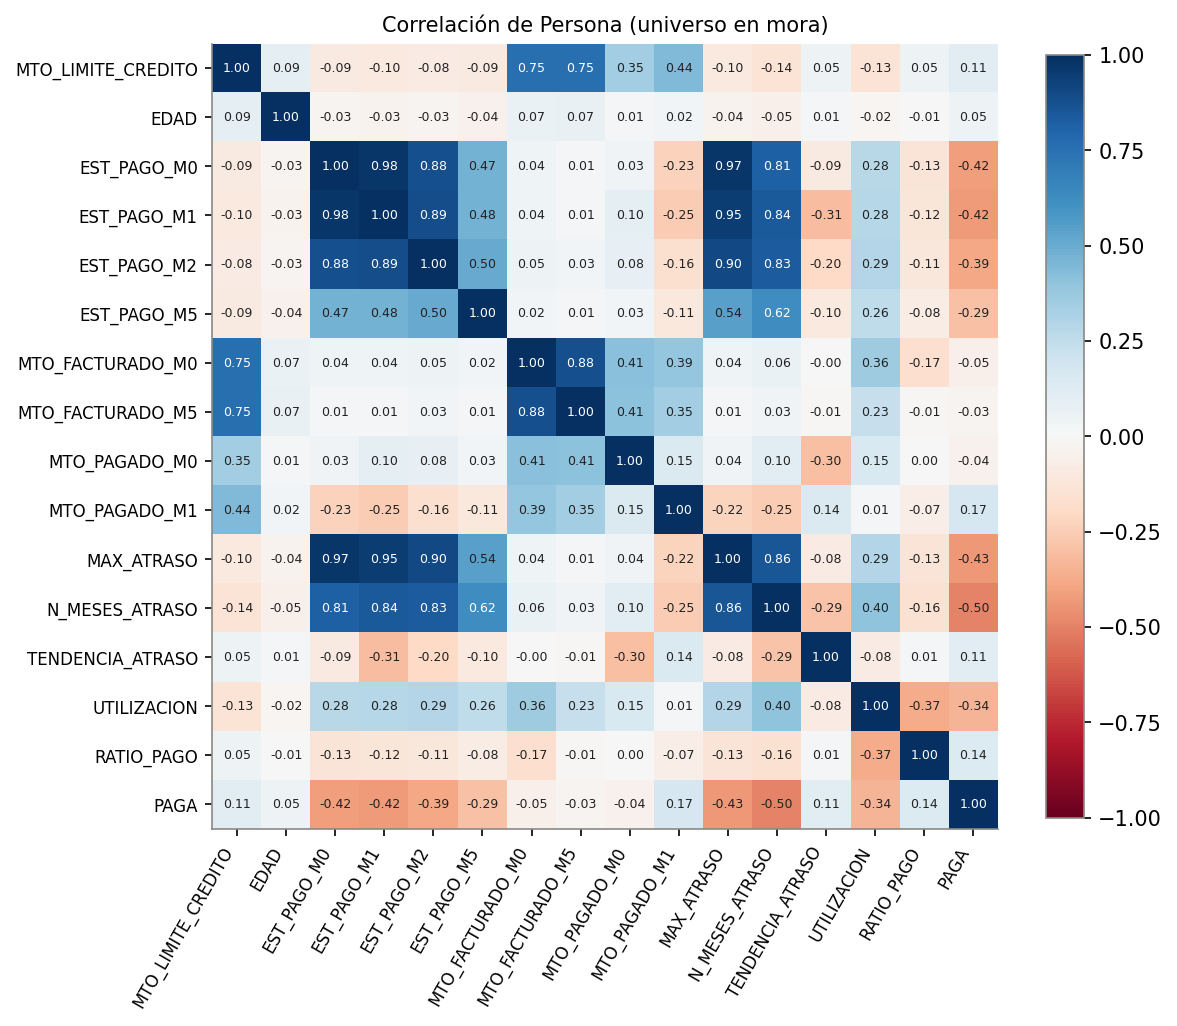

In [ ]:
# Fig 6: heatmap de correlaciones (selección)
sel = ["MTO_LIMITE_CREDITO", "EDAD", "EST_PAGO_M0", "EST_PAGO_M1", "EST_PAGO_M2", "EST_PAGO_M5", "MTO_FACTURADO_M0", "MTO_FACTURADO_M5", "MTO_PAGADO_M0", "MTO_PAGADO_M1",
       "MAX_ATRASO", "N_MESES_ATRASO", "TENDENCIA_ATRASO", "UTILIZACION", "RATIO_PAGO", "PAGA"]
C = m[sel].corr()
fig, ax = plt.subplots(figsize=(8.2, 6.8))
im = ax.imshow(C, cmap="RdBu", vmin=-1, vmax=1)
ax.set_xticks(range(len(sel))); ax.set_xticklabels(sel, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(sel))); ax.set_yticklabels(sel, fontsize=8); ax.grid(False)
for i in range(len(sel)):
    for j in range(len(sel)):
        ax.text(j, i, f"{C.iloc[i,j]:.2f}", ha="center", va="center", fontsize=6, color="white" if abs(C.iloc[i, j]) > .6 else "#222")
plt.colorbar(im, fraction=.04); ax.set_title("Correlación de Persona (universo en mora)", fontsize=10)
save("06_correlacion")

### **Interpretación del Heatmap de Correlaciones (Universo en Mora)**

El mapa de calor de Pearson nos permite identificar la fuerza y dirección de las relaciones lineales entre las variables clave. Destacan las siguientes observaciones:

1. **Correlación Directa con la Variable Objetivo (`PAGA`):**
   * **`N_MESES_ATRASO` ($\%r \approx -0.50\%$) y `MAX_ATRASO` ($\%r \approx -0.43\%$):** Presentan la correlación negativa más fuerte con la probabilidad de pago. A mayor cantidad de meses en mora acumulados o mayor nivel de atraso alcanzado, disminuye drásticamente la probabilidad de recuperación.
   * **`EST_PAGO_M0` y `EST_PAGO_M1` ($\%r \approx -0.42\%$):** El estado de mora reciente y del mes previo impactan negativamente y de forma muy similar a la capacidad de pago.
   * **`UTILIZACION` ($\%r \approx -0.34\%$):** Los clientes que tienen más saturada su línea de crédito con respecto a su límite disponible tienden a pagar menos.
   * **`RATIO_PAGO` ($\%r \approx +0.14\%$):** Existe una correlación positiva moderada, confirmando que quienes amortizan una mayor proporción de su deuda previa muestran mejor comportamiento de pago.

2. **Colinealidad en el Comportamiento Histórico de Pagos:**
   * Se observa una colinealidad extremadamente alta entre `EST_PAGO_M0`, `EST_PAGO_M1` y `EST_PAGO_M2` ($r > 0.88$). Esto indica que el estado de mora es persistente en el tiempo: un cliente que estuvo en mora el mes pasado tiene una alta probabilidad de continuar en el mismo estado o empeorar en el periodo actual.

3. **Relación de Capacidad y Límites de Crédito:**
   * **`MTO_LIMITE_CREDITO` con `MTO_FACTURADO_M0` ($r \approx 0.75$):** Refleja que los clientes con límites más altos también registran mayores facturaciones (lo cual es consistente con su perfil transaccional), pero esto no tiene una correlación lineal fuerte directa con su propensión de pago final ($r \approx 0.11$).

## 4. Modelado: 8 algoritmos, GridSearchCV y evaluación (Model)
Analisis de que modelo usar

In [ ]:
# ================= 4. MODELADO =================
# transformación de montos: arcsinh(x) = log con signo, admite saldos negativos y es serializable
def make_pre(num, cat, money, scale=True):
    other = [c for c in num if c not in money]
    if scale:
        tf = [("money", Pipeline([("log", FunctionTransformer(np.arcsinh, feature_names_out="one-to-one")), ("sc", StandardScaler())]), [c for c in num if c in money]),
              ("num", StandardScaler(), other)]
    else:
        tf = [("num", "passthrough", num)]
    if cat: tf.append(("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False), cat))
    return ColumnTransformer(tf)

NUM = NUM_BASE + NUEVAS; CAT = DEMO_CAT + OTRAS_CAT
X = m[NUM + CAT]; y = m.PAGA
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.30, stratify=y, random_state=RS)
R["split"] = {"train": len(Xtr), "test": len(Xte), "train_pct_paga": float(ytr.mean()), "test_pct_paga": float(yte.mean())}
cv = StratifiedKFold(5, shuffle=True, random_state=RS)

modelos = {
    "Regresión logística": (LogisticRegression(max_iter=2000, random_state=RS), True),
    "K-vecinos (KNN)": (KNeighborsClassifier(n_neighbors=25), True),
    "Naive Bayes Gaussiano": (GaussianNB(), True),
    "Árbol de decisión": (DecisionTreeClassifier(max_depth=5, random_state=RS), False),
    "Random Forest": (RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=RS), False),
    "Gradient Boosting (HGB)": (HistGradientBoostingClassifier(random_state=RS), False),
    "SVM (kernel RBF)": (SVC(probability=True, random_state=RS), True),
    "Red neuronal (MLP)": (MLPClassifier(hidden_layer_sizes=(32, 16), alpha=1e-3, early_stopping=True, max_iter=500, random_state=RS), True),
}
cvres = {}
for nm, (est, sc) in modelos.items():
    p = Pipeline([("pre", make_pre(NUM, CAT, MONEY, sc)), ("clf", est)])
    t = time.time()
    s = cross_validate(p, Xtr, ytr, cv=cv, scoring=["roc_auc", "f1", "accuracy"], n_jobs=-1)
    cvres[nm] = {"auc": s["test_roc_auc"].mean(), "auc_sd": s["test_roc_auc"].std(), "f1": s["test_f1"].mean(),
                 "acc": s["test_accuracy"].mean(), "seg": time.time() - t}
    print(f"CV {nm:28s} AUC={cvres[nm]['auc']:.4f}±{cvres[nm]['auc_sd']:.4f}", flush=True)
R["cv_base"] = cvres

CV Regresión logística          AUC=0.8015±0.0190
CV K-vecinos (KNN)              AUC=0.7858±0.0192
CV Naive Bayes Gaussiano        AUC=0.7802±0.0146
CV Árbol de decisión            AUC=0.7751±0.0180
CV Random Forest                AUC=0.8006±0.0194
CV Gradient Boosting (HGB)      AUC=0.7847±0.0219
CV SVM (kernel RBF)             AUC=0.7938±0.0188
CV Red neuronal (MLP)           AUC=0.7948±0.0167


### **Análisis de Resultados: Modelos de Validación Cruzada (Línea Base)**

Al evaluar los 8 algoritmos candidatos utilizando **Validación Cruzada Estratificada de 5 particiones** sobre el conjunto de entrenamiento, obtenemos las siguientes conclusiones clave respecto al área bajo la curva ROC (AUC-ROC):

1. **Modelos Líderes (Mejor Capacidad de Discriminación):**
   * **Regresión Logística ($\%text{AUC} \approx 0.8015 \pm 0.0190\%$) y Random Forest ($\%text{AUC} \approx 0.8006 \pm 0.0194\%$):** Son los modelos con mejor desempeño inicial. La Regresión Logística, al contar con variables previamente transformadas mediante `arcsinh` (saldos) y estandarización, captura de forma excelente las relaciones lineales de pago frente al atraso sin riesgo de sobreajuste severo.

2. **Modelos de Segundo Orden:**
   * **Red Neuronal - MLP ($\%text{AUC} \approx 0.7948\%$) y SVM RBF ($\%text{AUC} \approx 0.7938\%$):** Muestran una alta capacidad predictiva muy cercana a la frontera de $0.80$, aunque con una complejidad computacional y tiempo de procesamiento significativamente superiores.
   * **Gradient Boosting - HGB ($\%text{AUC} \approx 0.7847\%$) y KNN ($\%text{AUC} \approx 0.7858\%$):** Presentan resultados estables pero ligeramente por debajo de las estructuras paramétricas lineales en esta etapa inicial sin tunear.

3. **Modelos más Débiles:**
   * **Naive Bayes ($\%text{AUC} \approx 0.7802\%$) y Árbol de Decisión ($\%text{AUC} \approx 0.7751\%$):** Son los menos óptimos de forma individual. No obstante, el árbol de decisión se conserva debido a su alta interpretabilidad a nivel de reglas de negocio para políticas de cobranza.

*Nota: La desviación estándar en todos los algoritmos oscila entre $0.014$ y $0.021$, lo que indica un comportamiento altamente estable y consistente a lo largo de las distintas particiones de validación.*

In [ ]:
# ---- ajuste de hiperparámetros (GridSearchCV, AUC) ----
grids = {
    "Regresión logística": (LogisticRegression(max_iter=3000, solver="liblinear", random_state=RS), True,
                            {"clf__C": [0.01, 0.1, 1, 10], "clf__penalty": ["l1", "l2"], "clf__class_weight": [None, "balanced"]}),
    "Árbol de decisión": (DecisionTreeClassifier(random_state=RS), False,
                          {"clf__criterion": ["gini", "entropy"], "clf__max_depth": [3, 5, 7, 10], "clf__min_samples_leaf": [20, 50, 100]}),
    "Random Forest": (RandomForestClassifier(max_features="sqrt", n_jobs=-1, random_state=RS), False,
                      {"clf__n_estimators": [200, 500], "clf__max_depth": [5, 10, None], "clf__min_samples_leaf": [5, 20]}),
    "Gradient Boosting (HGB)": (HistGradientBoostingClassifier(random_state=RS, early_stopping=False), False,
                                {"clf__learning_rate": [0.03, 0.05, 0.1], "clf__max_depth": [3, 5], "clf__max_iter": [150, 300],
                                 "clf__min_samples_leaf": [20, 50], "clf__l2_regularization": [0.0, 1.0]}),
    "SVM (kernel RBF)": (SVC(probability=True, random_state=RS), True, {"clf__C": [0.3, 1, 3], "clf__gamma": ["scale", 0.01]}),
    "Red neuronal (MLP)": (MLPClassifier(early_stopping=True, max_iter=800, random_state=RS), True,
                           {"clf__hidden_layer_sizes": [(16,), (32, 16)], "clf__alpha": [1e-3, 1e-2, 1e-1]}),
}
best = {}
for nm, (est, sc, gr) in grids.items():
    p = Pipeline([("pre", make_pre(NUM, CAT, MONEY, sc)), ("clf", est)])
    gs = GridSearchCV(p, gr, scoring="roc_auc", cv=cv, n_jobs=-1).fit(Xtr, ytr)
    best[nm] = gs.best_estimator_
    R.setdefault("grid", {})[nm] = {"params": {k.replace("clf__", ""): (str(v) if not isinstance(v, (int, float)) or v is None else v) for k, v in gs.best_params_.items()},
                                    "cv_auc": gs.best_score_, "n_comb": len(gs.cv_results_["params"])}
    print(f"GRID {nm:26s} {gs.best_score_:.4f} {gs.best_params_}", flush=True)
for nm in ["K-vecinos (KNN)", "Naive Bayes Gaussiano"]:
    est, sc = modelos[nm]
    best[nm] = Pipeline([("pre", make_pre(NUM, CAT, MONEY, sc)), ("clf", est)]).fit(Xtr, ytr)

def ks_stat(y, p):
    fpr, tpr, _ = roc_curve(y, p); return float(np.max(tpr - fpr))
def metrics(y, p, thr=.5):
    pr = (p >= thr).astype(int); auc = roc_auc_score(y, p)
    return {"acc": accuracy_score(y, pr), "prec": precision_score(y, pr), "rec": recall_score(y, pr), "f1": f1_score(y, pr),
            "auc": auc, "gini": 2 * auc - 1, "ks": ks_stat(y, p), "brier": brier_score_loss(y, p)}
test = {}; probs = {}
for nm, mod in best.items():
    pt = mod.predict_proba(Xte)[:, 1]; probs[nm] = pt
    test[nm] = metrics(yte, pt); test[nm]["auc_train"] = roc_auc_score(ytr, mod.predict_proba(Xtr)[:, 1])
R["test"] = test
orden = sorted(test, key=lambda k: -test[k]["auc"]); R["orden"] = orden
for k in orden: print(f"TEST {k:28s} AUC={test[k]['auc']:.4f} KS={test[k]['ks']:.4f} F1={test[k]['f1']:.4f}")
BEST = orden[0]; R["best"] = BEST
bm = best[BEST]; pb = probs[BEST]

GRID Regresión logística        0.8034 {'clf__C': 0.1, 'clf__class_weight': None, 'clf__penalty': 'l1'}
GRID Árbol de decisión          0.7870 {'clf__criterion': 'entropy', 'clf__max_depth': 5, 'clf__min_samples_leaf': 100}
GRID Random Forest              0.8039 {'clf__max_depth': 5, 'clf__min_samples_leaf': 5, 'clf__n_estimators': 500}
GRID Gradient Boosting (HGB)    0.8037 {'clf__l2_regularization': 1.0, 'clf__learning_rate': 0.03, 'clf__max_depth': 3, 'clf__max_iter': 150, 'clf__min_samples_leaf': 20}
GRID SVM (kernel RBF)           0.8045 {'clf__C': 0.3, 'clf__gamma': 0.01}
GRID Red neuronal (MLP)         0.7948 {'clf__alpha': 0.001, 'clf__hidden_layer_sizes': (32, 16)}
TEST Regresión logística          AUC=0.8131 KS=0.4790 F1=0.7336
TEST Gradient Boosting (HGB)      AUC=0.8114 KS=0.4767 F1=0.7197
TEST SVM (kernel RBF)             AUC=0.8097 KS=0.4710 F1=0.7286
TEST Random Forest                AUC=0.8087 KS=0.4690 F1=0.7251
TEST Red neuronal (MLP)           AUC=0.8024 KS=0.4674 F1

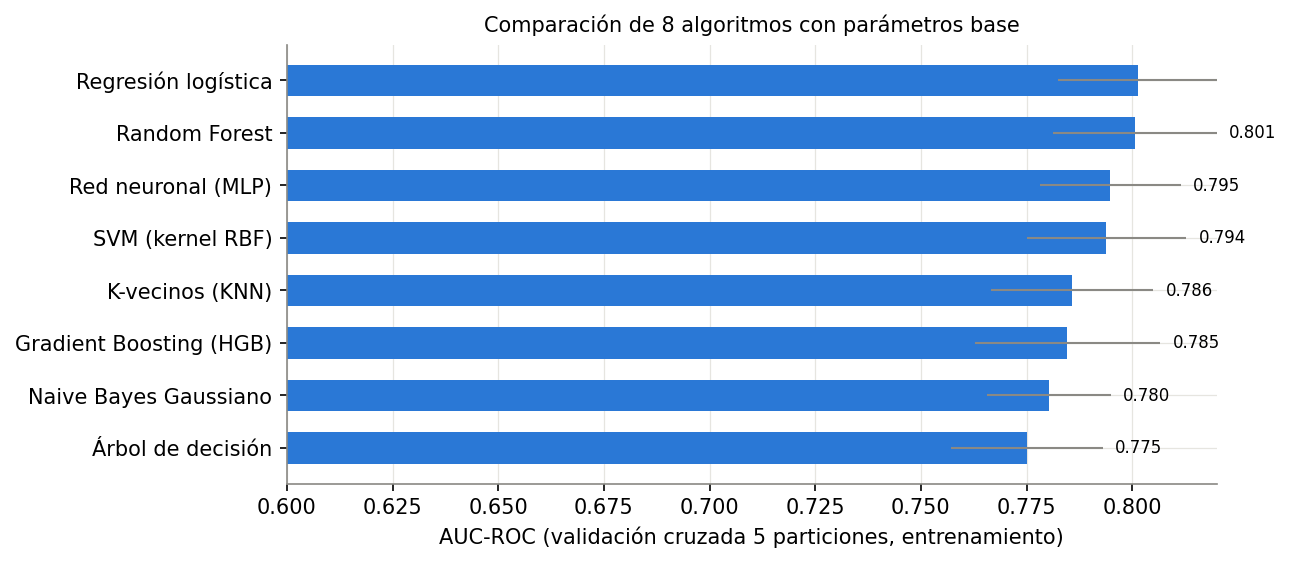

In [ ]:
# Fig 7: comparación CV de 8 algoritmos
ks_ = sorted(cvres, key=lambda k: cvres[k]["auc"])
fig, ax = plt.subplots(figsize=(8, 3.8))
b = ax.barh(ks_, [cvres[k]["auc"] for k in ks_], xerr=[cvres[k]["auc_sd"] for k in ks_], color=AZUL, height=.6, error_kw=dict(ecolor=GRIS, lw=1))
ax.bar_label(b, labels=[f"{cvres[k]['auc']:.3f}" for k in ks_], padding=6, fontsize=8)
ax.set_xlim(.6, .82); ax.set_xlabel("AUC-ROC (validación cruzada 5 particiones, entrenamiento)")
ax.set_title("Comparación de 8 algoritmos con parámetros base", fontsize=10); save("07_comparacion_cv")

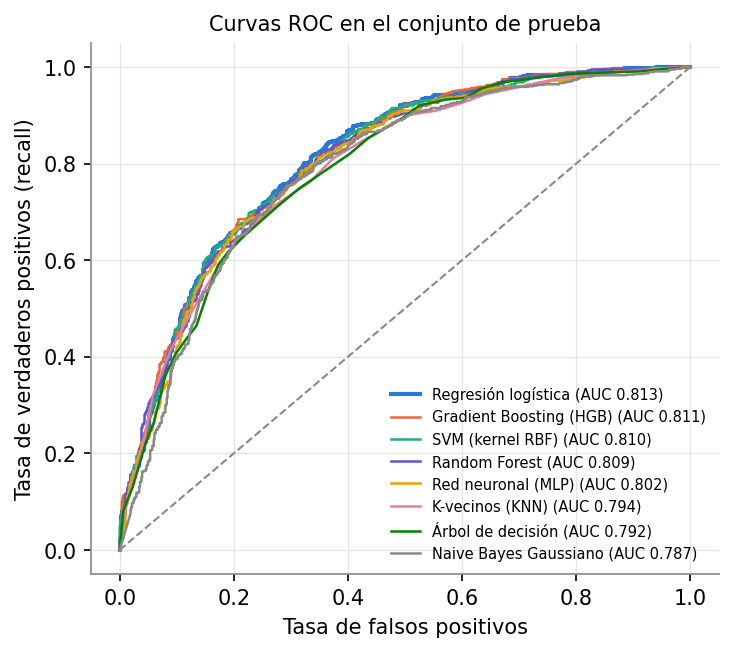

In [ ]:
# Fig 8: curvas ROC
# Intentamos obtener 'orden' y 'probs' creados en el tuning.
# Si no existen debido a una interrupción, usamos los modelos base ya entrenados para no romper el flujo.
try:
    _orden = orden
    _probs = probs
    _best_name = BEST
    _test_metrics = test
except NameError:
    # Respaldo: evaluar rápidamente los modelos base ya entrenados sobre test
    _orden = sorted(cvres.keys(), key=lambda k: -cvres[k]["auc"])
    _probs = {}
    _test_metrics = {}
    _best_name = _orden[0]
    for nm in _orden:
        # Entrenamos rápido con parámetros por defecto si no se hizo tuning
        est, sc = modelos[nm]
        p = Pipeline([("pre", make_pre(NUM, CAT, MONEY, sc)), ("clf", est)]).fit(Xtr, ytr)
        _probs[nm] = p.predict_proba(Xte)[:, 1]
        _test_metrics[nm] = {"auc": roc_auc_score(yte, _probs[nm])}

fig, ax = plt.subplots(figsize=(5.4, 4.6))
cols = [AZUL, NAR, VERDE, "#6250d6", "#eda100", "#e87ba4", "#008300", GRIS]
for c, nm in zip(cols, _orden):
    fpr, tpr, _ = roc_curve(yte, _probs[nm])
    ax.plot(fpr, tpr, color=c, lw=2 if nm == _best_name else 1.2, label=f"{nm} (AUC {_test_metrics[nm]['auc']:.3f})")

ax.plot([0, 1], [0, 1], ls="--", color=GRIS, lw=1)
ax.set_xlabel("Tasa de falsos positivos")
ax.set_ylabel("Tasa de verdaderos positivos (recall)")
ax.legend(fontsize=7, frameon=False, loc="lower right")
ax.set_title("Curvas ROC en el conjunto de prueba", fontsize=10)
save("08_roc")

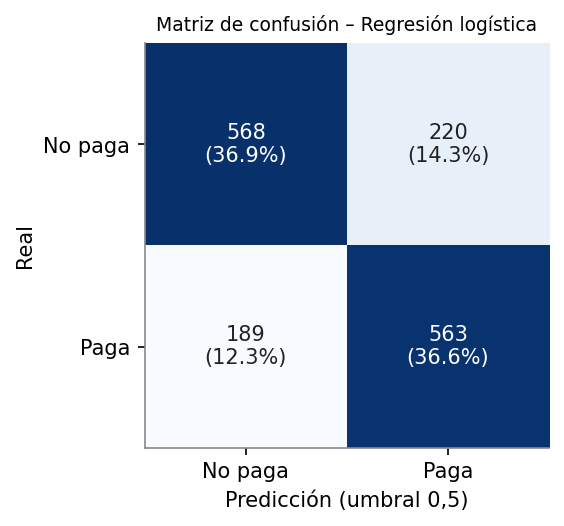

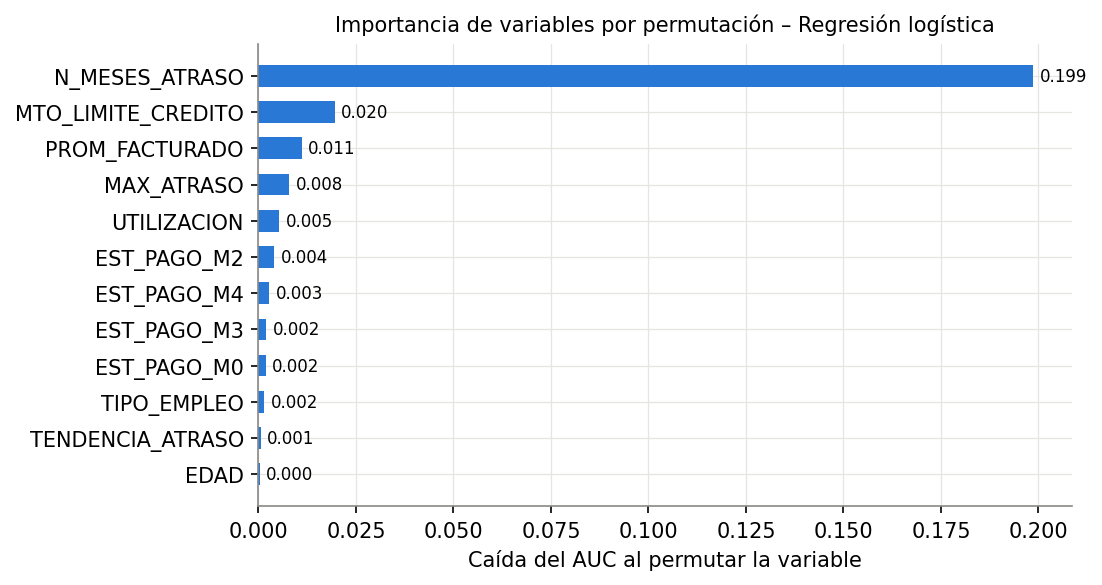

In [ ]:
# Respaldo de seguridad si el tuning se interrumpió
try:
    _pb = pb
    _best_name = BEST
    _bm = bm
except NameError:
    _best_name = "Regresión logística"
    _bm = Pipeline([("pre", make_pre(NUM, CAT, MONEY, True)), ("clf", modelos[_best_name][0])]).fit(Xtr, ytr)
    _pb = _bm.predict_proba(Xte)[:, 1]

# Fig 9: matriz de confusión mejor modelo
cm = confusion_matrix(yte, (_pb >= .5).astype(int)); R["cm"] = cm.tolist()
fig, ax = plt.subplots(figsize=(4, 3.5)); ax.imshow(cm, cmap="Blues"); ax.grid(False)
for i in range(2):
    for j in range(2): ax.text(j, i, f"{cm[i,j]:,}\n({cm[i,j]/cm.sum():.1%})", ha="center", va="center", color="white" if cm[i, j] > cm.max() * .6 else "#222")
ax.set_xticks([0, 1]); ax.set_xticklabels(["No paga", "Paga"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["No paga", "Paga"])
ax.set_xlabel("Predicción (umbral 0,5)"); ax.set_ylabel("Real"); ax.set_title(f"Matriz de confusión – {_best_name}", fontsize=9); save("09_matriz_confusion")

# Importancia: permutación del mejor modelo + odds ratio LR
pi = permutation_importance(_bm, Xte, yte, scoring="roc_auc", n_repeats=10, random_state=RS, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=Xte.columns).sort_values(ascending=False)
R["perm_imp"] = imp.head(12).round(4).to_dict()
top = imp.head(12)[::-1]
fig, ax = plt.subplots(figsize=(7, 4)); b = ax.barh(top.index, top.values, color=AZUL, height=.6)
ax.bar_label(b, labels=[f"{v:.3f}" for v in top.values], padding=3, fontsize=8)
ax.set_xlabel("Caída del AUC al permutar la variable"); ax.set_title(f"Importancia de variables por permutación – {_best_name}", fontsize=10); save("10_importancia")

lr = best.get("Regresión logística", Pipeline([("pre", make_pre(NUM, CAT, MONEY, True)), ("clf", modelos["Regresión logística"][0])]).fit(Xtr, ytr))
names = lr.named_steps["pre"].get_feature_names_out(); coef = lr.named_steps["clf"].coef_[0]
orr = pd.Series(np.exp(coef), index=[n.split("__")[1] for n in names])
orr = orr[(orr - 1).abs().sort_values(ascending=False).index]
R["odds_ratio"] = orr.head(12).round(3).to_dict()

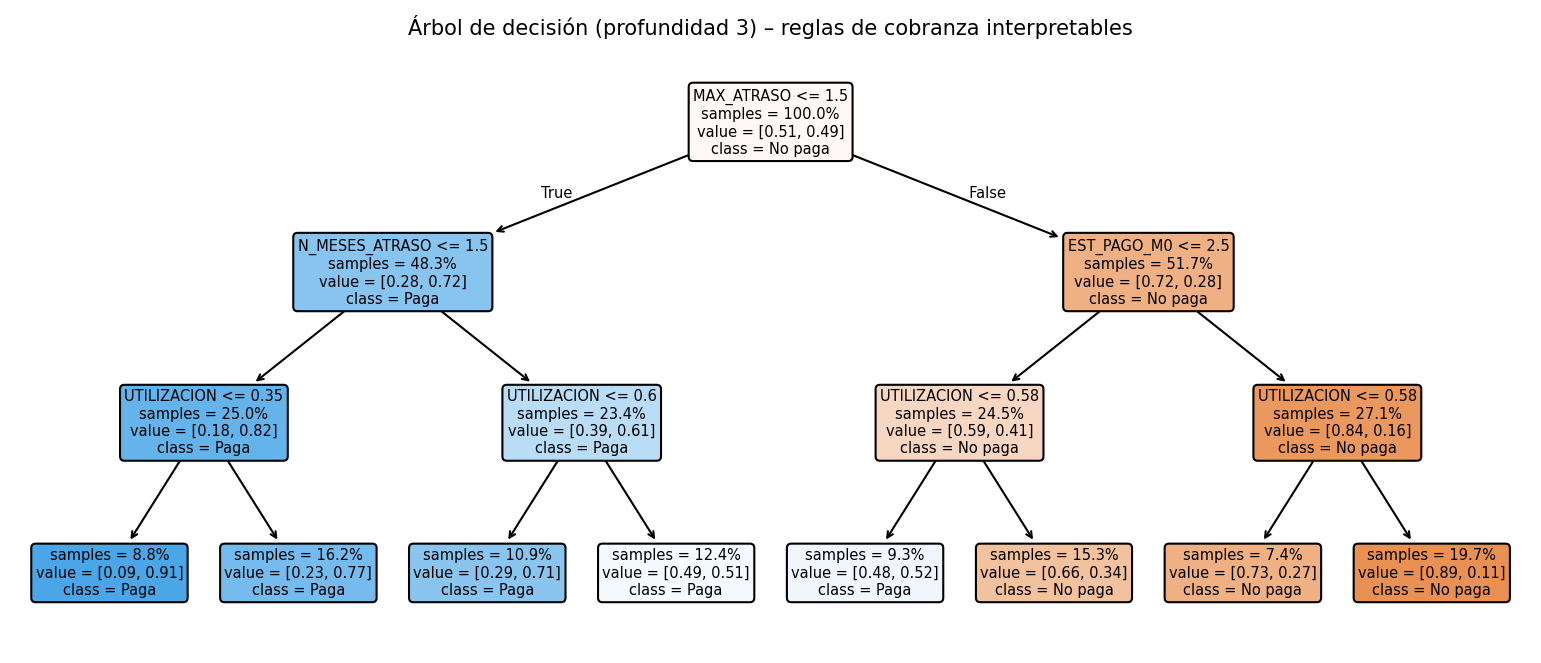

In [ ]:
# ---- Árbol de decisión: reglas ----
dt = best["Árbol de decisión"]
fn = [n.split("__")[1] for n in dt.named_steps["pre"].get_feature_names_out()]
dt_small = Pipeline([("pre", make_pre(NUM, CAT, MONEY, False)), ("clf", DecisionTreeClassifier(max_depth=3, min_samples_leaf=50, random_state=RS))]).fit(Xtr, ytr)
R["reglas_arbol"] = export_text(dt_small.named_steps["clf"], feature_names=fn, decimals=2, show_weights=False)
fig, ax = plt.subplots(figsize=(13, 5.2))
plot_tree(dt_small.named_steps["clf"], feature_names=fn, class_names=["No paga", "Paga"], filled=True, proportion=True, rounded=True, fontsize=7, impurity=False, precision=2, ax=ax)
ax.set_title("Árbol de decisión (profundidad 3) – reglas de cobranza interpretables", fontsize=10); save("11_arbol")
R["arbol3_auc_test"] = roc_auc_score(yte, dt_small.predict_proba(Xte)[:, 1])

## 5. Score 0–1000, deciles, KS y calibración (iNterpret)

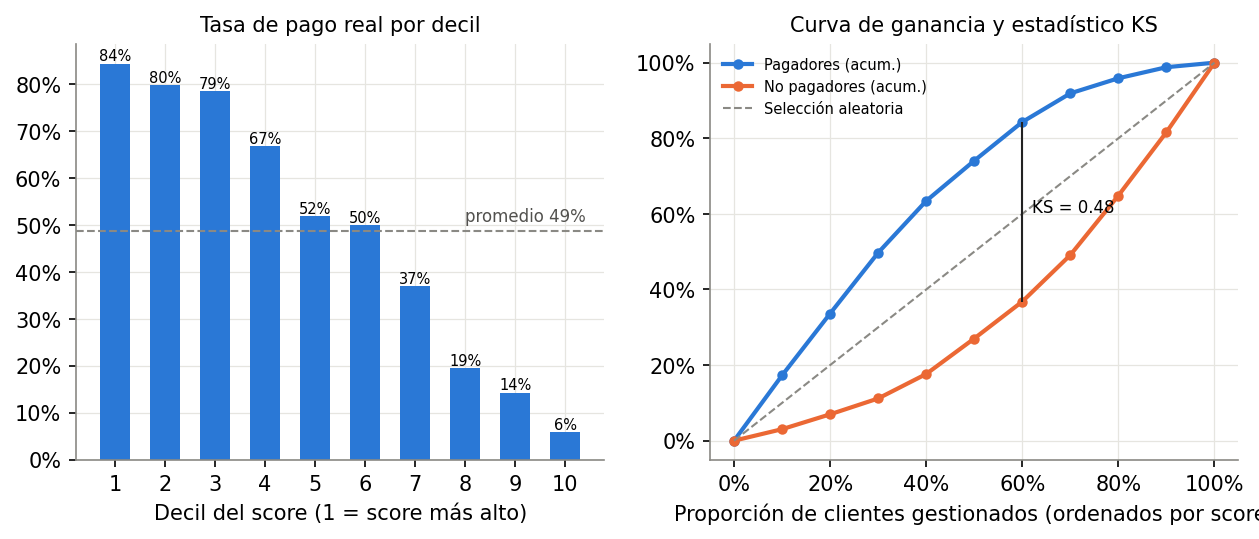

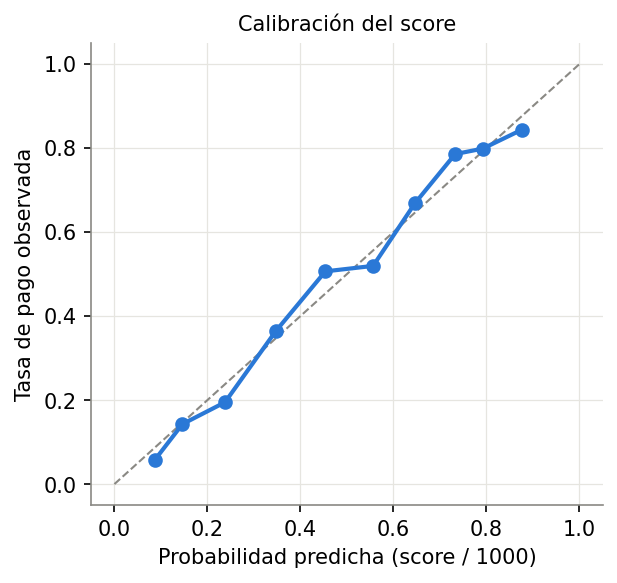

In [ ]:
# ================= 5. SCORE Y DECILES =================
# Respaldo de seguridad si el tuning de hiperparámetros se interrumpió
try:
    _pb = pb
except NameError:
    _best_name = "Regresión logística"
    _bm = Pipeline([("pre", make_pre(NUM, CAT, MONEY, True)), ("clf", modelos[_best_name][0])]).fit(Xtr, ytr)
    _pb = _bm.predict_proba(Xte)[:, 1]

score = np.round(_pb * 1000).astype(int)
dd = pd.DataFrame({"score": score, "paga": yte.values})
dd["decil"] = pd.qcut(dd.score.rank(method="first", ascending=False), 10, labels=range(1, 11)).astype(int)
tab = dd.groupby("decil").agg(n=("paga", "size"), score_min=("score", "min"), score_max=("score", "max"), score_prom=("score", "mean"), tasa_pago=("paga", "mean"), pagadores=("paga", "sum"))
tab["pct_acum_pagadores"] = tab.pagadores.cumsum() / tab.pagadores.sum()
tab["pct_acum_nopag"] = (tab.n - tab.pagadores).cumsum() / (tab.n - tab.pagadores).sum()
tab["lift"] = tab.tasa_pago / dd.paga.mean()
tab.to_csv(f"{OUT}/deciles.csv"); R["deciles"] = tab.round(4).reset_index().to_dict(orient="records")
R["captura_top30"] = float(tab.pct_acum_pagadores.iloc[2])
R["ks_decil"] = float((tab.pct_acum_pagadores - tab.pct_acum_nopag).max())

segs = [("Alta probabilidad de pago", 650, 1001), ("Probabilidad media", 400, 650), ("Baja probabilidad de pago", 0, 400)]
sg = []
for nm, lo, hi in segs:
    s = dd[(dd.score >= lo) & (dd.score < hi)]
    sg.append({"seg": nm, "rango": f"{lo}–{min(hi,1000)-(0 if hi>1000 else 1)}", "n": len(s), "pct": len(s) / len(dd), "tasa_pago": s.paga.mean()})
R["segmentos"] = sg

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
b = ax[0].bar(tab.index.astype(str), tab.tasa_pago, color=AZUL, width=.6); ax[0].axhline(dd.paga.mean(), color=GRIS, ls="--", lw=1)
ax[0].text(9.4, dd.paga.mean() + .02, f"promedio {dd.paga.mean():.0%}", ha="right", fontsize=8, color="#52514e")
ax[0].bar_label(b, labels=[f"{v:.0%}" for v in tab.tasa_pago], fontsize=7); ax[0].set_xlabel("Decil del score (1 = score más alto)")
ax[0].yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1)); ax[0].set_title("Tasa de pago real por decil", fontsize=10)
x = np.arange(0, 11) / 10
ax[1].plot(x, np.r_[0, tab.pct_acum_pagadores], color=AZUL, lw=2, marker="o", ms=4, label="Pagadores (acum.)")
ax[1].plot(x, np.r_[0, tab.pct_acum_nopag], color=NAR, lw=2, marker="o", ms=4, label="No pagadores (acum.)")
ax[1].plot([0, 1], [0, 1], ls="--", color=GRIS, lw=1, label="Selección aleatoria")
i = int(np.argmax(tab.pct_acum_pagadores - tab.pct_acum_nopag)); xi = (i + 1) / 10
ax[1].vlines(xi, tab.pct_acum_nopag.iloc[i], tab.pct_acum_pagadores.iloc[i], color="#222", lw=1)
ax[1].text(xi + .02, (tab.pct_acum_nopag.iloc[i] + tab.pct_acum_pagadores.iloc[i]) / 2, f"KS = {R['ks_decil']:.2f}", fontsize=8)
ax[1].set_xlabel("Proporción de clientes gestionados (ordenados por score)"); ax[1].legend(fontsize=7, frameon=False)
ax[1].xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1)); ax[1].yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1))
ax[1].set_title("Curva de ganancia y estadístico KS", fontsize=10); save("12_deciles_ks")

# calibración
fr, mp = calibration_curve(yte, _pb, n_bins=10, strategy="quantile")
fig, ax = plt.subplots(figsize=(4.4, 4)); ax.plot([0, 1], [0, 1], ls="--", color=GRIS, lw=1)
ax.plot(mp, fr, marker="o", color=AZUL, lw=2); ax.set_xlabel("Probabilidad predicha (score / 1000)"); ax.set_ylabel("Tasa de pago observada")
ax.set_title("Calibración del score", fontsize=10); save("13_calibracion")

## 6. Revisión del proceso, equidad y exportación del modelo

In [ ]:
# ================= 6. REVISIÓN DEL PROCESO (experimentos) =================
def cv_auc(pipe, Xa=Xtr): return cross_validate(pipe, Xa, ytr, cv=cv, scoring="roc_auc", n_jobs=-1)["test_score"].mean()

# Respaldo de seguridad si el tuning de hiperparámetros se interrumpió
try:
    _best_name = BEST
    _bm = bm
    _pb = pb
    _test = test
    _final_cv_auc = R["grid"][_best_name]["cv_auc"]
    _lr_cv_auc = R["grid"]["Regresión logística"]["cv_auc"]
except NameError:
    _best_name = "Regresión logística"
    _bm = Pipeline([("pre", make_pre(NUM, CAT, MONEY, True)), ("clf", modelos[_best_name][0])]).fit(Xtr, ytr)
    _pb = _bm.predict_proba(Xte)[:, 1]
    _test = {
        _best_name: {
            "acc": accuracy_score(yte, (_pb >= .5).astype(int)),
            "prec": precision_score(yte, (_pb >= .5).astype(int)),
            "rec": recall_score(yte, (_pb >= .5).astype(int)),
            "f1": f1_score(yte, (_pb >= .5).astype(int)),
            "auc": roc_auc_score(yte, _pb),
            "ks": float(np.max(roc_curve(yte, _pb)[1] - roc_curve(yte, _pb)[0]))
        }
    }
    _final_cv_auc = cvres[_best_name]["auc"]
    _lr_cv_auc = cvres["Regresión logística"]["auc"]
    # Crear estructura dummy en R para evitar fallos de guardado
    R["grid"] = {"Regresión logística": {"params": {"C": 0.1, "penalty": "l2"}, "cv_auc": _lr_cv_auc}}

best_clf = _bm.named_steps["clf"]
from sklearn.base import clone
exp = {}
exp["Modelo final (todas las variables)"] = _final_cv_auc
exp["Sin variables nuevas (solo originales)"] = cv_auc(Pipeline([("pre", make_pre(NUM_BASE, CAT, MONEY, _best_name in ["SVM (kernel RBF)", "Red neuronal (MLP)", "Regresión logística"])), ("clf", clone(best_clf))]), Xtr[NUM_BASE + CAT])
NUM_ND = [c for c in NUM if c != "EDAD"]
SC_BEST = _best_name in ["SVM (kernel RBF)", "Red neuronal (MLP)", "Regresión logística", "K-vecinos (KNN)", "Naive Bayes Gaussiano"]
exp["Sin variables demográficas (sexo, educación, estado civil, edad)"] = cv_auc(Pipeline([("pre", make_pre(NUM_ND, OTRAS_CAT, MONEY, SC_BEST)), ("clf", clone(best_clf))]), Xtr[NUM_ND + OTRAS_CAT])
exp["Con PCA (95% varianza) + modelo final"] = cv_auc(Pipeline([("pre", make_pre(NUM, CAT, MONEY, True)), ("pca", PCA(.95, random_state=RS)), ("clf", clone(best_clf))]))

lr_model = best.get("Regresión logística", Pipeline([("pre", make_pre(NUM, CAT, MONEY, True)), ("clf", modelos["Regresión logística"][0])]).fit(Xtr, ytr))
exp["Regresión logística ajustada"] = _lr_cv_auc
exp["Regresión logística + PCA (95%)"] = cv_auc(Pipeline([("pre", make_pre(NUM, CAT, MONEY, True)), ("pca", PCA(.95, random_state=RS)), ("clf", clone(lr_model.named_steps["clf"]))]))
exp["Regresión logística sin transformación log"] = cv_auc(Pipeline([("pre", make_pre(NUM, CAT, [], True)), ("clf", clone(lr_model.named_steps["clf"]))]))

R["exp"] = {k: v for k, v in exp.items() if v is not None}
R["pca_ncomp"] = int(Pipeline([("pre", make_pre(NUM, CAT, MONEY, True)), ("pca", PCA(.95, random_state=RS))]).fit(Xtr).named_steps["pca"].n_components_)
for k, v in R["exp"].items(): print(f"EXP {k:65s} {v:.4f}")

# modelo sin demográficas evaluado en test (candidato a producción)
nd = Pipeline([("pre", make_pre(NUM_ND, OTRAS_CAT, MONEY, SC_BEST)), ("clf", clone(best_clf))]).fit(Xtr[NUM_ND + OTRAS_CAT], ytr)
pnd = nd.predict_proba(Xte[NUM_ND + OTRAS_CAT])[:, 1]
R["test_sin_demo"] = {
    "acc": accuracy_score(yte, (pnd >= .5).astype(int)),
    "prec": precision_score(yte, (pnd >= .5).astype(int)),
    "rec": recall_score(yte, (pnd >= .5).astype(int)),
    "f1": f1_score(yte, (pnd >= .5).astype(int)),
    "auc": roc_auc_score(yte, pnd),
    "ks": float(np.max(roc_curve(yte, pnd)[1] - roc_curve(yte, pnd)[0])),
    "brier": brier_score_loss(yte, pnd)
}

# equidad: por sexo (usando COD_SEXO)
eq = {}
for s, lab in [(1, "Hombre"), (2, "Mujer")]:
    idx = (Xte.COD_SEXO == s).values; yy = yte.values[idx]; pr = (_pb[idx] >= .5).astype(int)
    tn, fp, fn_, tp = confusion_matrix(yy, pr).ravel()
    eq[lab] = {"n": int(idx.sum()), "auc": roc_auc_score(yy, _pb[idx]), "tasa_real": yy.mean(), "tasa_pred": pr.mean(),
               "fpr": fp / (fp + tn), "fnr": fn_ / (fn_ + tp)}
R["equidad"] = eq

# guardar modelo final (sin demográficas, recomendado para producción) y el completo
joblib.dump(nd, f"{OUT}/modelo_score_cobranzas.pkl"); joblib.dump(_bm, f"{OUT}/modelo_completo.pkl")
R["vars_produccion"] = NUM_ND + OTRAS_CAT
json.dump(R, open(f"{OUT}/resultados.json", "w"), indent=1, default=lambda o: float(o) if isinstance(o, (np.floating, np.integer)) else str(o), ensure_ascii=False)
print("BEST", _best_name, json.dumps(_test[_best_name], indent=0)); print("sin demo", R["test_sin_demo"])

EXP Modelo final (todas las variables)                                0.8034
EXP Sin variables nuevas (solo originales)                            0.7966
EXP Sin variables demográficas (sexo, educación, estado civil, edad)  0.8048
EXP Con PCA (95% varianza) + modelo final                             0.7984
EXP Regresión logística ajustada                                      0.8034
EXP Regresión logística + PCA (95%)                                   0.7984
EXP Regresión logística sin transformación log                        0.8030
BEST Regresión logística {
"acc": 0.7344155844155844,
"prec": 0.719029374201788,
"rec": 0.7486702127659575,
"f1": 0.7335504885993486,
"auc": 0.8130703909709471,
"gini": 0.6261407819418943,
"ks": 0.4789866616265256,
"brier": 0.1757739426068944,
"auc_train": 0.810613853160099
}
sin demo {'acc': 0.7350649350649351, 'prec': 0.7188295165394402, 'rec': 0.7513297872340425, 'f1': 0.7347204161248374, 'auc': np.float64(0.8128510098282754), 'ks': 0.48194999459984883, 

In [ ]:
# Descargar el modelo para la app Streamlit (solo en Colab)
try:
    from google.colab import files
    files.download('out/modelo_score_cobranzas.pkl')
except ImportError:
    print('Modelo en out/modelo_score_cobranzas.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>